In [1]:
# M24CA1L306 Data Science Lab - Lab Exercise #18
# Student: Abhinav | MAC25MCA-2002 | S3 MCA (2025-27)
# Dataset: <PLACEHOLDER - replace with your heart disease CSV filename>
#          Expected columns: age, sex, cp, trestbps, chol, fbs, restecg,
#                            thalach, exang, oldpeak, slope, ca, thal, target
# Task: AdaBoost Classification for heart disease prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay, classification_report,
    roc_auc_score, roc_curve
)


In [2]:

# ─────────────────────────────────────────────
# Load and preprocess
# ─────────────────────────────────────────────
df = pd.read_csv("../Datasets/Heart_Disease.csv")

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:\n", df.isnull().sum())


Shape: (1025, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [3]:

# PLACEHOLDER: adjust target column name if different
target_col = "target"

X = df.drop(target_col, axis=1).values
y = df[target_col].values
feature_names = df.drop(target_col, axis=1).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [4]:

# ─────────────────────────────────────────────
# Train AdaBoost
# ─────────────────────────────────────────────
base = DecisionTreeClassifier(max_depth=1)
ada = AdaBoostClassifier(estimator=base, n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
y_pred      = ada.predict(X_test)
y_pred_prob = ada.predict_proba(X_test)[:, 1]


In [5]:

# ─────────────────────────────────────────────
# Q1: Accuracy
# ─────────────────────────────────────────────
print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.8878048780487805


Correctly classified   : 182  (TN=85, TP=97)
Incorrectly classified : 23  (FP=15, FN=8)


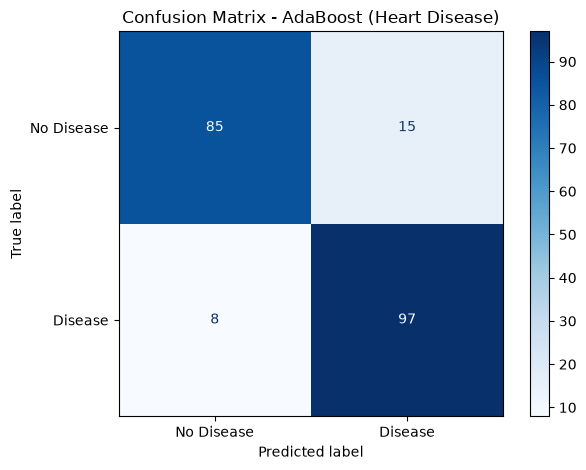

In [7]:

# ─────────────────────────────────────────────
# Q2: Confusion Matrix
# ─────────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Correctly classified   : {tn + tp}  (TN={tn}, TP={tp})")
print(f"Incorrectly classified : {fp + fn}  (FP={fp}, FN={fn})")

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["No Disease", "Disease"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - AdaBoost (Heart Disease)")
plt.tight_layout()
plt.savefig("../Outputs/lab-18_Output/lab18_confusion_matrix.png", dpi=100)
plt.show()


In [8]:

# ─────────────────────────────────────────────
# Q3: Precision, Recall, F1
# ─────────────────────────────────────────────
print(classification_report(y_test, y_pred,
                             target_names=["No Disease", "Disease"]))


              precision    recall  f1-score   support

  No Disease       0.91      0.85      0.88       100
     Disease       0.87      0.92      0.89       105

    accuracy                           0.89       205
   macro avg       0.89      0.89      0.89       205
weighted avg       0.89      0.89      0.89       205



AUC Score: 0.9574


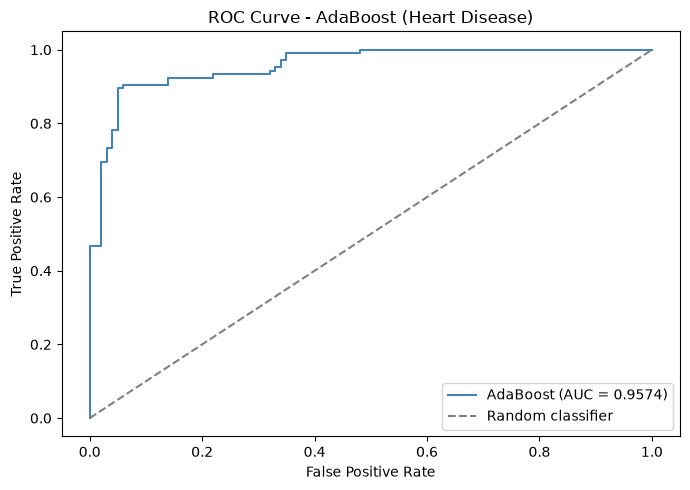

In [9]:

# ─────────────────────────────────────────────
# Q4: ROC Curve and AUC
# ─────────────────────────────────────────────
auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC Score: {auc:.4f}")

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="steelblue", label=f"AdaBoost (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - AdaBoost (Heart Disease)")
plt.legend()
plt.tight_layout()
plt.savefig("../Outputs/lab-18_Output/lab18_roc_curve.png", dpi=100)
plt.show()


  chol           : 0.1823
  oldpeak        : 0.1780
  thalach        : 0.1588
  age            : 0.0967
  trestbps       : 0.0955
  ca             : 0.0910
  cp             : 0.0646
  thal           : 0.0455
  sex            : 0.0426
  slope          : 0.0257
  exang          : 0.0194
  fbs            : 0.0000
  restecg        : 0.0000


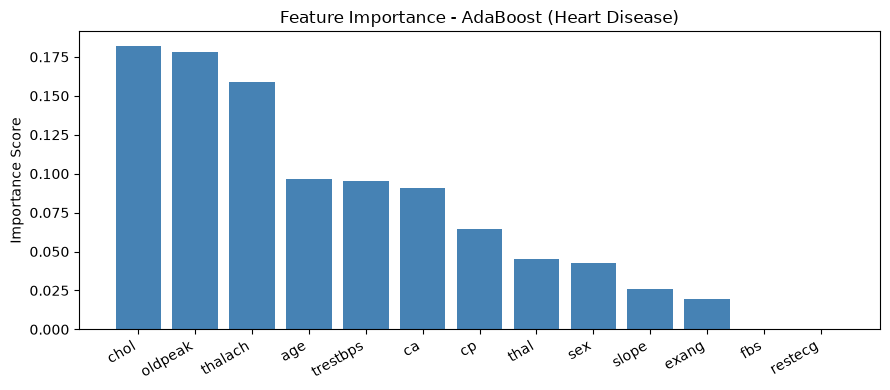

In [10]:

# ─────────────────────────────────────────────
# Q5: Feature Importance
# ─────────────────────────────────────────────
importances = ada.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

for fname, imp in sorted(zip(feature_names, importances),
                          key=lambda x: x[1], reverse=True):
    print(f"  {fname:15s}: {imp:.4f}")

plt.figure(figsize=(9, 4))
plt.bar([feature_names[i] for i in sorted_idx],
        [importances[i] for i in sorted_idx], color="steelblue")
plt.title("Feature Importance - AdaBoost (Heart Disease)")
plt.ylabel("Importance Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("../Outputs/lab-18_Output/lab18_feature_importance.png", dpi=100)
plt.show()


  n_estimators=  10  ->  Accuracy: 0.8780
  n_estimators=  20  ->  Accuracy: 0.8732
  n_estimators=  30  ->  Accuracy: 0.8585
  n_estimators=  40  ->  Accuracy: 0.8634
  n_estimators=  50  ->  Accuracy: 0.8634
  n_estimators=  60  ->  Accuracy: 0.8683
  n_estimators=  70  ->  Accuracy: 0.8732
  n_estimators=  80  ->  Accuracy: 0.8634
  n_estimators=  90  ->  Accuracy: 0.8829
  n_estimators= 100  ->  Accuracy: 0.8878
  n_estimators= 110  ->  Accuracy: 0.8829
  n_estimators= 120  ->  Accuracy: 0.9122
  n_estimators= 130  ->  Accuracy: 0.9024
  n_estimators= 140  ->  Accuracy: 0.8878
  n_estimators= 150  ->  Accuracy: 0.9122
  n_estimators= 160  ->  Accuracy: 0.8976
  n_estimators= 170  ->  Accuracy: 0.9122
  n_estimators= 180  ->  Accuracy: 0.8829
  n_estimators= 190  ->  Accuracy: 0.9073
  n_estimators= 200  ->  Accuracy: 0.9073
Best n_estimators = 120 with accuracy = 0.9122


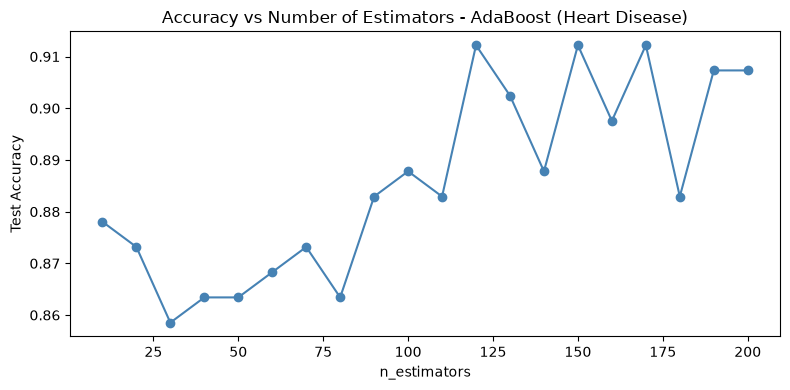


All tasks complete. Plots saved.


In [19]:

# ─────────────────────────────────────────────
# Q6: n_estimators comparison
# ─────────────────────────────────────────────
estimator_values = [n for n in range(10,201,10)]
estimator_accs   = []

for n in estimator_values:
    clf = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                             n_estimators=n, random_state=42)
    clf.fit(X_train, y_train)
    a = accuracy_score(y_test, clf.predict(X_test))
    estimator_accs.append(a)
    print(f"  n_estimators={n:4d}  ->  Accuracy: {a:.4f}")

best_n = estimator_values[estimator_accs.index(max(estimator_accs))]
print(f"Best n_estimators = {best_n} with accuracy = {max(estimator_accs):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(estimator_values, estimator_accs, marker="o", color="steelblue")
plt.xlabel("n_estimators")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Number of Estimators - AdaBoost (Heart Disease)")
plt.tight_layout()
plt.savefig("../Outputs/lab-18_Output/lab18_n_estimators.png", dpi=100)
plt.show()

print("\nAll tasks complete. Plots saved.")